# The Perceptron: Learning a Separating Boundary

## 1. Introduction and learning objectives

A perceptron combines measured inputs into a linear score and makes a hard class decision. Its learning rule reacts to an observation that lies on the wrong side of the current boundary, or exactly on that boundary. This gives an understandable bridge from linear classification to the units used in neural networks.

You will calculate scores and updates manually, relate them to boundary geometry, derive the perceptron loss interpretation, understand the assumptions behind finite-update convergence, and investigate a problem no single linear boundary can solve.

Recommended prerequisite: [Logistic Regression](../01-ml-fundamentals/logistic-regression.ipynb), especially the difference between probabilities and decisions. You can also read independently with basic vector algebra: the needed dot products, label convention, and geometric inequalities are explained here. The perceptron uses labels $-1$ and $+1$, not the $0/1$ convention used for probabilistic binary losses.

Try each exercise in its dedicated answer cell first. A collapsed **Show hint** and a separate **Show worked solution — try the exercise first** follow immediately below it. Reference Python is displayed text and is not executed by Run All; some snippets name earlier references in this chapter.

### Working environment

Run this setup cell before working on the implementation challenges. It imports numerical and plotting tools, without defining any exercise solution.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 4.01 — Translate the target convention

**Type:** Conceptual · **Answer:** Markdown

Explain how you would convert a dataset labeled zero and one to minus one and plus one, and how you would convert predictions back. State why changing a label convention requires checking a learning rule rather than changing only a plot legend.

**Expected outcome:** Explicit conversions and a discussion of how label values enter the update.

**Your response to Exercise 4.01**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 4.01**

Find an affine conversion that sends zero to minus one and one to plus one.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 4.01**

Convert with $y_{\pm}=2y_{01}-1$ and invert with $y_{01}=(y_{\pm}+1)/2$. The inverse only produces valid binary labels when its input is restricted to minus/plus one.

The label enters the signed score and the update multiplicatively. Leaving negative examples encoded as zero would make their signed score always zero and their update contribution vanish, changing the algorithm rather than only its presentation.

</details>

## 2. Prerequisites and mathematical foundations

### Linear scores and a decision convention

Here $\mathbb R$ denotes the real numbers, $\mathbb R^d$ denotes a vector with $d$ real entries, and $\in$ means membership in that set. Let $x_i\in\mathbb R^d$ be the feature vector of observation $i$, where $d$ is the number of features, and let $y_i\in\{-1,+1\}$ be its label. The real-valued parameters are $w\in\mathbb R^d$ and scalar intercept $b$. The score is

$$
z_i=x_i^Tw+b=\sum_{j=1}^d x_{ij}w_j+b.
$$

The index $j$ labels features, $T$ denotes transpose, and the dot product sums products of corresponding coordinates. Our explicit prediction convention is $\hat y_i=+1$ for $z_i\geq0$ and $\hat y_i=-1$ for $z_i<0$. Thus a zero score is predicted as the positive class. A score is not a probability: it is unbounded, and its magnitude changes when all parameters are multiplied by a positive constant.

The **signed score** $y_i z_i$ packages both labels into one expression. It is positive when an observation lies strictly on its labeled side, negative when on the opposite side, and zero on the boundary. The update rule below uses $y_i z_i\leq0$. This includes boundary points even when our positive tie prediction happens to equal the target. Count these as **margin violations**, not exclusively incorrect predicted labels.

### Exercise 4.02 — Read signed scores

**Type:** Numerical · **Answer:** Markdown

Use $w=(1,-2)^T$, $b=1$, and examples $(x,y)=((1,0),+1)$, $((0,1),-1)$, and $((1,1),+1)$. Calculate each score, predicted class, signed score, and whether the update condition is met.

**Expected outcome:** A table that treats a boundary tie consistently with both the stated prediction and update conventions.

**Your response to Exercise 4.02**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 4.02**

A tie can be predicted positive while still meeting the margin-violation update rule.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 4.02**

| Input and label | Score | Prediction | Signed score | Update? |
| --- | ---: | ---: | ---: | --- |
| $(1,0),+1$ | $2$ | $+1$ | $2$ | No |
| $(0,1),-1$ | $-1$ | $-1$ | $1$ | No |
| $(1,1),+1$ | $0$ | $+1$ | $0$ | Yes |

Prediction uses $z\geq0$, whereas the update condition is $yz\leq0$. These are intentionally different conventions at the boundary.

</details>

### Geometry and the intercept

In two dimensions the boundary $w_1x_1+w_2x_2+b=0$ is a line. In more dimensions it is a hyperplane: a flat set with one fewer dimension than the feature space, provided $w\ne0$. The vector $w$ is perpendicular to that boundary. Moving an input by $t w$ changes the score by $t\lVert w\rVert_2^2$, where $\lVert w\rVert_2=\sqrt{\sum_jw_j^2}$ is its Euclidean length.

The signed perpendicular distance for a labeled example is $y_i z_i/\lVert w\rVert_2$ when $w\ne0$. Dividing by weight length makes distance independent of positive rescalings of both $w$ and $b$. This geometric distance depends on feature units; metres and millimetres create different coordinate geometry.

The intercept shifts a boundary away from the origin. For convenient algebra define augmented features $\widetilde x_i=(1,x_{i1},\ldots,x_{id})^T$ and parameters $\theta=(b,w_1,\ldots,w_d)^T$. Then $z_i=\theta^T\widetilde x_i$. The first augmented coordinate is constant, so updating its weight updates the intercept. Keep this parameter order consistent when implementing the augmented version.

### Exercise 4.03 — Verify boundary invariance

**Type:** Mathematical · **Answer:** Markdown

Multiply both $w$ and $b$ by a positive scalar $c$. Show what happens to the score, predicted labels, signed score, and signed perpendicular distance. Explain why a negative scalar is a different case.

**Expected outcome:** Four algebraic comparisons and a careful treatment of sign and the zero-score convention.

**Your response to Exercise 4.03**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 4.03**

Compare how the numerator and denominator of geometric distance scale.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 4.03**

For $c>0$, the new score is $z'=c(w^Tx+b)=cz$. Its sign and zero status are unchanged, so predicted classes and violation decisions are preserved. The signed score becomes $cyz$.

For $w\ne0$, $\lVert cw\rVert_2=c\lVert w\rVert_2$, so signed perpendicular distance is unchanged:
$$
\frac{ycz}{\lVert cw\rVert_2}=\frac{yz}{\lVert w\rVert_2}.
$$
For negative $c$, nonzero scores change sign, exchanging positive and negative sides. Exact zero scores still use the stated positive tie prediction. A zero weight vector has no defined perpendicular-distance normalization.

</details>

## 3. Theoretical development and worked examples

### The update rule

Choose a learning rate $\eta>0$. When $y_i z_i\leq0$, update

$$
w_{\mathrm{new}}=w+\eta y_i x_i,\qquad
b_{\mathrm{new}}=b+\eta y_i.
$$

If $y_i z_i>0$, leave parameters unchanged. Both changes use the same example and pre-update score. The augmented form is $\theta_{\mathrm{new}}=\theta+\eta y_i\widetilde x_i$.

Why does this help the selected example? Substitute into its new score:

$$
y_i z_{i,\mathrm{new}}
=y_i z_i+\eta y_i^2(x_i^Tx_i+1)
=y_i z_i+\eta(\lVert x_i\rVert_2^2+1).
$$

The equality $y_i^2=1$ uses our label convention. A violation update therefore increases that example's signed score by a positive amount, including the intercept contribution. It need not make that example correct immediately, and it can reduce another example's score.

**Worked update.** Start with zero weights/intercept, take $x=(1,2)^T$, $y=-1$, and $\eta=1/2$. The zero score is a violation. New weights are $(-1/2,-1)^T$ and the intercept is $-1/2$. The new score on this example is $-1/2-2-1/2=-3$, so its signed score has increased from zero to three. This arithmetic explains one update without supplying a training routine.

### Exercise 4.04 — Work through changing parameter states

**Type:** Numerical · **Answer:** Markdown

Start with $w=(0,0)^T$, $b=0$, and $\eta=1$. Process $((2,1),+1)$, then $((1,2),-1)$, then revisit the first observation. At each visit, compute the current score before deciding whether to update.

**Expected outcome:** A chronological table of pre-update scores, violation decisions, and post-visit parameters. Do not evaluate all scores at the initial parameters.

**Your response to Exercise 4.04**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 4.04**

Recompute the score when revisiting the first observation.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 4.04**

| Visit | Pre-update score | Violation? | New weights | New bias |
| --- | ---: | --- | --- | ---: |
| $(2,1),+1$ | $0$ | Yes | $(2,1)$ | $1$ |
| $(1,2),-1$ | $2+2+1=5$ | Yes | $(1,-1)$ | $0$ |
| Revisit $(2,1),+1$ | $2-1=1$ | No | $(1,-1)$ | $0$ |

The second label reverses the update direction. The final visit uses the changed parameter state rather than the original zero weights.

</details>

### A loss interpretation and a nondifferentiable decision

The hard decision function jumps at zero. Its derivative is zero away from that point and does not exist at the jump, so treating its derivative like a sigmoid derivative would not provide a useful ordinary training gradient.

Instead, define the individual **perceptron loss**

$$
\ell_i(w,b)=\max(0,-y_i z_i).
$$

The function $\max$ returns its largest argument. Strictly correct signed scores have zero loss; negative signed scores have positive loss proportional to the violation. In that negative region,

$$
\nabla_w\ell_i=-y_i x_i,\qquad
\frac{\partial\ell_i}{\partial b}=-y_i.
$$

The symbol $\nabla_w$ collects weight partial derivatives into a vector, and $\partial/\partial b$ denotes the intercept partial derivative. Subtracting $\eta$ times these derivatives gives the perceptron update. At a zero signed score the loss has a corner. A **subgradient** is a slope supporting a convex function from below; at this corner any value between the two one-sided gradient vectors is valid. Our rule chooses the violation-side vector, which explains why it updates a boundary point even though its current loss is zero.

This is not the margin-one hinge loss $\max(0,1-y_i z_i)$ and is not binary cross-entropy. A successful separator can still have very small positive margins and no calibrated probability interpretation.

### Exercise 4.05 — Compare two learning signals

**Type:** Conceptual · **Answer:** Markdown

Compare the response of perceptron loss and logistic cross-entropy to a correctly classified observation that is very close to the boundary. Explain why a hard prediction is insufficient to tell you whether these objectives would change parameters.

**Expected outcome:** A distinction between decision correctness, margin, probability confidence, and the training objective.

**Your response to Exercise 4.05**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 4.05**

A correct class decision need not mean the objective has zero derivative.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 4.05**

For a strictly positive signed score, perceptron loss is zero and the stated perceptron rule makes no update. Logistic cross-entropy still penalizes uncertainty: a finite correct score near zero gives a probability near one half and an individual derivative $p-y$ that is generally nonzero.

Thus both models can predict the correct label while providing different learning signals. At exactly zero margin, our perceptron convention chooses a nonzero violation-side subgradient, even though its current loss is zero. Classification alone therefore does not specify training behavior.

</details>

### Separability and what convergence means

A finite dataset is **strictly linearly separable** if some $w,b$ satisfy $y_i(x_i^Tw+b)>0$ for every observation. For example, the two-input OR rule labels $(0,0)$ negative and the other three binary inputs positive. The chosen weights $w=(1,1)^T$, $b=-1/2$ strictly separate those four points. A strict separator needs no points on its boundary.

Training repeatedly visits observations, often over shuffled epochs. An epoch is one complete pass. If a full pass makes no violation updates, the current parameters strictly separate the training data. Stop then, or at a declared maximum number of epochs. Reaching the budget does not establish separability or convergence. The final separator can depend on order and need not have the largest possible margin.

### Why a finite update bound is possible

The following proof explains the assumptions rather than requiring you to memorize a theorem. Use augmented inputs and suppose:

- Every $\lVert\widetilde x_i\rVert_2\leq R$, for a finite radius bound $R>0$.
- A unit vector $u$ exists with $y_i u^T\widetilde x_i\geq\gamma>0$ for all $i$.
- Start with $\theta=0$, use a fixed $\eta>0$, and update only on $y_i\theta^T\widetilde x_i\leq0$.

The word unit means $\lVert u\rVert_2=1$. Here $\gamma$ is an **augmented-space** margin: its normalization includes the intercept coordinate, so it is not the earlier distance normalized by $\lVert w\rVert_2$ alone. A finite strictly separable dataset admits positive $\gamma$ after normalizing a strict augmented separator.

After $K$ updates, movement toward $u$ is at least $K\eta\gamma$, because every update increases $u^T\theta$ by $\eta y_i u^T\widetilde x_i\geq\eta\gamma$. Meanwhile, expanding the squared length of an update gives

$$
\lVert\theta+\eta y_i\widetilde x_i\rVert_2^2
=\lVert\theta\rVert_2^2+2\eta y_i\theta^T\widetilde x_i
 +\eta^2\lVert\widetilde x_i\rVert_2^2
\leq\lVert\theta\rVert_2^2+\eta^2R^2.
$$

The middle term is nonpositive by the update condition. Starting from zero and applying the inequality $K$ times gives $\lVert\theta_K\rVert_2\leq\eta R\sqrt K$.

For a unit $u$, the projection cannot exceed total length: $u^T\theta_K\leq\lVert\theta_K\rVert_2$. This is a special case of the Cauchy–Schwarz inequality $|a^Tc|\leq\lVert a\rVert_2\lVert c\rVert_2$ for vectors $a,c$. Geometrically, a component cannot be longer than the whole vector. Combining both bounds yields

$$
K\eta\gamma\leq\eta R\sqrt K
\quad\Longrightarrow\quad
K\leq(R/\gamma)^2
$$

for $K>0$; the zero-update case is already finite. This is a bound on violation updates, not epochs or held-out accuracy. If examples continue to be revisited, infinitely many violations would contradict this finite bound. Without strict separability there is no such guarantee.

### Exercise 4.06 — Explain the update-bound assumptions

**Type:** Mathematical · **Answer:** Markdown

Identify the exact place in the proof that uses the violation condition and the place that uses a strict positive margin. Explain what fails if $\gamma=0$ and why the radius includes the constant intercept feature.

**Expected outcome:** An annotated reasoning chain linking assumptions to inequalities, not merely a restated final bound.

**Your response to Exercise 4.06**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 4.06**

Locate the cross term in the norm expansion and the accumulated projection onto the separator.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 4.06**

The update condition makes $2\eta y_i\theta^T\widetilde x_i\leq0$, allowing it to be dropped when upper-bounding squared parameter length. Strict margin gives a projection gain of at least $\eta\gamma$ on every update, yielding the lower bound $K\eta\gamma$.

If $\gamma=0$, that positive progress lower bound disappears and division by $\gamma$ is invalid. The radius uses augmented features because the intercept also changes; its constant coordinate contributes one to $\lVert\widetilde x_i\rVert^2=\lVert x_i\rVert^2+1$. Both bounds must refer to that same augmented geometry.

</details>

## 4. Guided exercises

### A task a linear boundary cannot solve

Exclusive OR, abbreviated XOR, labels $(1,0)$ and $(0,1)$ positive and $(0,0)$ and $(1,1)$ negative. Suppose a strict separator existed. The negative origin requires $b<0$. The two positive points require $w_1+b>0$ and $w_2+b>0$. Adding them gives $w_1+w_2+2b>0$, hence $w_1+w_2+b>-b>0$. But the negative point $(1,1)$ requires that same expression to be negative. This contradiction proves no strict linear separator exists in these two original coordinates.

The problem is representation, not a missing training epoch. Adding a nonlinear feature or a hidden nonlinear layer changes the available boundaries. It also changes the model, so it should not be described as merely tuning the original perceptron.

### Exercise 4.07 — Construct and verify a different logic boundary

**Type:** Mathematical · **Answer:** Markdown

For the AND rule, label $(1,1)$ positive and the other three binary inputs negative. Propose weights and an intercept giving strict separation, then verify all four inequalities.

**Expected outcome:** A manually constructed separator with no boundary ties, plus its four signed scores.

**Your response to Exercise 4.07**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 4.07**

Give the sum of two binary inputs a threshold strictly between one and two.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 4.07**

One valid choice is $w=(1,1)^T$, $b=-3/2$. For input order $(0,0),(0,1),(1,0),(1,1)$, scores are $(-3/2,-1/2,-1/2,1/2)$.

With AND labels $(-1,-1,-1,+1)$, signed scores are $(3/2,1/2,1/2,1/2)$, all strictly positive. No observation lies on the boundary. Many positive rescalings or other strict separators are equally valid.

</details>

### Exercise 4.08 — Diagnose non-convergence

**Type:** Critical · **Answer:** Markdown

A perceptron repeatedly updates on XOR. Explain why more epochs or a different constant learning rate cannot create a strict linear separator. Propose a representation change and state what additional mathematical machinery its training might require.

**Expected outcome:** A diagnosis based on the function family rather than an unsupported claim about optimization speed.

**Your response to Exercise 4.08**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 4.08**

The existence of a separator is a property of the function family and data, not of the update budget.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 4.08**

The XOR inequalities are contradictory for a single affine score in two original features. More epochs or a changed rate cannot make such a separator exist.

One representation change adds feature $x_1x_2$. On binary corners, the score $x_1+x_2-2x_1x_2-1/2$ separates XOR. A perceptron can still learn a linear boundary in that expanded space; the boundary is nonlinear in original coordinates. Alternatively, learned nonlinear hidden units require an appropriate differentiable loss, local activation derivatives, and backpropagation. These change the model rather than merely tuning its old optimizer.

</details>

## 5. Implementation challenges

Use $X$ with shape `(n, d)`, labels `(n,)`, weights `(d,)`, and a scalar intercept. Keep the zero-score prediction convention and the zero-signed-score update condition separate in your code.

### Exercise 4.09 — Implement a perceptron pass

**Type:** Programming · **Answer:** Code

Write a function that visits a supplied sequence of observation indices once and applies the stated update on each violation. Accept and return weights/intercept, and report the number of updates. Compute each decision from the current parameter state.

**Expected outcome:** A pass checked against a manual sequence and a tie case. There should be no automatic training loop hidden in prediction.

In [ ]:
# Your code for Exercise 4.09.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 4.09**

Work on copies and evaluate each score immediately before its own conditional update.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 4.09**

The pass accepts an explicitly supplied index sequence. The training routine will supply a full permutation; manual traces can intentionally revisit indices.

~~~python
def perceptron_pass(X, y, w, b, order, learning_rate=1.0):
    X, y, w = map(lambda a: np.asarray(a, float), (X, y, w))
    order = np.asarray(order)
    if (X.ndim != 2 or len(X) == 0 or y.shape != (len(X),)
            or w.shape != (X.shape[1],) or np.ndim(b) != 0):
        raise ValueError("Incompatible feature, label, or parameter shapes")
    if not np.isin(y, [-1, 1]).all():
        raise ValueError("Perceptron labels must be -1 or +1")
    if not all(np.isfinite(a).all() for a in (X, y, w, np.asarray(b))):
        raise ValueError("Data and parameters must be finite")
    if not np.isfinite(learning_rate) or learning_rate <= 0:
        raise ValueError("Learning rate must be positive and finite")
    if (order.ndim != 1 or not np.issubdtype(order.dtype, np.integer)
            or np.any(order < 0) or np.any(order >= len(X))):
        raise ValueError("Invalid observation indices")
    w, b = w.copy(), float(b)
    updates = 0
    for index in order:
        score = X[index] @ w + b
        if y[index] * score <= 0:
            w = w + learning_rate * y[index] * X[index]
            b = b + learning_rate * y[index]
            updates += 1
    return w, b, updates

ref_w, ref_b, ref_updates = perceptron_pass(
    [[2, 1], [1, 2]], [1, -1], [0, 0], 0, [0, 1, 0])
np.testing.assert_allclose(ref_w, [1, -1])
assert ref_b == 0 and ref_updates == 2
~~~

</details>

### Exercise 4.10 — Implement training with an honest stopping report

**Type:** Programming · **Answer:** Code

Build a training routine using your pass function. Support fixed order or seeded shuffling, a positive rate, and an epoch budget. Stop after a complete pass with no violation updates. Return a history and a flag explaining whether a strict separator was found.

**Expected outcome:** A reproducible separator on a suitable dataset and a budget-exhausted report on XOR, without claiming universal convergence.

In [ ]:
# Your code for Exercise 4.10.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 4.10**

A zero-update full pass is a different stopping signal from a low but nonzero violation count.

Distinguish budget exhaustion, a zero-update pass, and the strict signed scores of the final state.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 4.10**

This uses Solution 4.09. The history reports epoch, violation updates, training accuracy, and minimum signed score. A final strict separator can be recognized even if the budget ends before a confirming zero-update pass.

~~~python
def train_perceptron(X, y, epochs=100, learning_rate=1.,
                     seed=0, shuffle=True):
    X, y = np.asarray(X, float), np.asarray(y, float)
    if X.ndim != 2 or not isinstance(epochs, int) or epochs < 0:
        raise ValueError("Invalid features or epoch budget")
    w, b = np.zeros(X.shape[1]), 0.
    perceptron_pass(X, y, w, b, np.array([], dtype=int), learning_rate)
    rng = np.random.default_rng(seed)
    history = []
    converged = False
    for epoch in range(1, epochs + 1):
        order = rng.permutation(len(X)) if shuffle else np.arange(len(X))
        w, b, updates = perceptron_pass(X, y, w, b, order, learning_rate)
        scores = X @ w + b
        predicted = np.where(scores >= 0, 1, -1)
        history.append((epoch, updates, np.mean(predicted == y),
                        np.min(y * scores)))
        if updates == 0:
            converged = True
            break
    strict = bool(np.all(y * (X @ w + b) > 0))
    return {"w": w.copy(), "b": b, "history": np.array(history).reshape(-1, 4),
            "converged": converged, "strictly_separated": strict,
            "status": "zero-update pass" if converged else "budget exhausted"}
~~~

The explicit budget prevents an infinite loop on nonseparable data. Accuracy alone is insufficient to certify strict separation when tie predictions exist.

</details>

### Exercise 4.11 — Test the geometry and conventions

**Type:** Programming · **Answer:** Code

Write checks for predictions, tie handling, invalid labels, incompatible shapes, and intercept updates. Verify that a positive rescaling of a nonzero parameter vector preserves its predictions. Include a case where forgetting the intercept changes the representable boundary.

**Expected outcome:** Small checks that protect the mathematical contract rather than reproducing the implementation line by line.

In [ ]:
# Your code for Exercise 4.11.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 4.11**

Include a zero-input negative example, which needs an intercept under the stated positive tie rule.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 4.11**

This checks both numerical behavior and rejected inputs using Solution 4.09.

~~~python
ref_w, ref_b, count = perceptron_pass([[0, 0]], [1], [0, 0], 0, [0])
assert count == 1 and ref_b == 1
np.testing.assert_array_equal(ref_w, [0, 0])
ref_X = np.array([[0.], [1.]])
ref_labels = np.array([-1., 1.])
ref_scores = ref_X @ np.array([1.]) - 0.5
np.testing.assert_array_equal(np.where(ref_scores >= 0, 1, -1), ref_labels)
np.testing.assert_array_equal(
    np.where(ref_scores >= 0, 1, -1),
    np.where(7 * ref_scores >= 0, 1, -1))
for operation in [
    lambda: perceptron_pass([[1]], [0], [0], 0, [0]),
    lambda: perceptron_pass([[1]], [1], [[0]], 0, [0]),
]:
    try:
        operation()
    except ValueError:
        pass
    else:
        raise AssertionError("Invalid perceptron input was accepted")
~~~

With zero intercept, input zero always has score zero and is predicted positive, so its negative label cannot be represented by changing weights alone.

</details>

## 6. Experiments and visualizations

The next demonstration compares two datasets with fixed, hand-chosen geometry. It contains no fitted estimator or learning loop. The line illustrates the OR separator already discussed; the alternating corners of XOR provide the contrasting visual pattern.

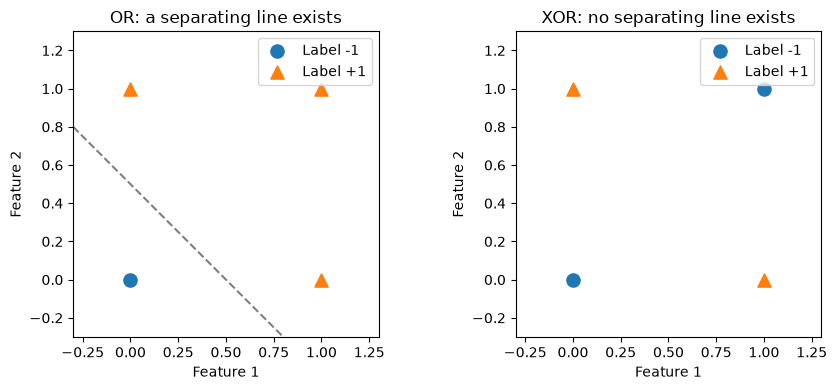

In [5]:
import numpy as np
import matplotlib.pyplot as plt

demo_corners = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
demo_or_labels = np.array([-1, 1, 1, 1])
demo_xor_labels = np.array([-1, 1, 1, -1])
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, demo_labels, demo_title in zip(axes, (demo_or_labels, demo_xor_labels), ("OR: a separating line exists", "XOR: no separating line exists")):
    for label, marker in [(-1, "o"), (1, "^")]:
        chosen = demo_labels == label
        ax.scatter(demo_corners[chosen, 0], demo_corners[chosen, 1], marker=marker, s=90, label=f"Label {label:+d}")
    ax.set(xlim=(-0.3, 1.3), ylim=(-0.3, 1.3), xlabel="Feature 1", ylabel="Feature 2", title=demo_title)
    ax.set_aspect("equal")
    ax.legend()
demo_axis = np.linspace(-0.3, 0.8, 100)
axes[0].plot(demo_axis, 0.5 - demo_axis, "--", color="gray", label="Chosen boundary")
fig.tight_layout()
plt.show()

The next dataset is generated with a strict score gap around a known boundary. Removing small-gap candidates ensures the retained observations are strictly separable, rather than assuming a sampled Gaussian cloud must be separable. The supplied scoring expression creates labels only; you will fit your own parameters. The split separates training observations from held-out observations.

In [6]:
demo_rng = np.random.default_rng(404)
demo_candidates = demo_rng.uniform(-2.0, 2.0, size=(400, 2))
demo_known_scores = demo_candidates[:, 0] - 0.6 * demo_candidates[:, 1] + 0.2
demo_keep = np.abs(demo_known_scores) > 0.25
demo_X = demo_candidates[demo_keep][:80]
demo_y = np.where(demo_known_scores[demo_keep][:80] > 0, 1, -1)
demo_ids = demo_rng.permutation(len(demo_X))
demo_train_ids, demo_test_ids = demo_ids[:60], demo_ids[60:]
print("Dataset shape:", demo_X.shape, "class counts:", np.unique(demo_y, return_counts=True))
print("Training / held-out sizes:", len(demo_train_ids), len(demo_test_ids))

Dataset shape: (80, 2) class counts: (array([-1,  1]), array([39, 41]))
Training / held-out sizes: 60 20


### Exercise 4.12 — Investigate order and the final separator

**Type:** Experimental · **Answer:** Code

Fit the supplied training set with at least five shuffle seeds and a fixed budget. Record violation updates, strict-separation status, and held-out accuracy. Plot the final boundaries for runs that separate the training set.

**Expected outcome:** Reproducible histories showing whether identical training success implies identical parameters or boundaries. Treat the theoretical bound as a guarantee under assumptions, not a prediction of the exact update count.

In [ ]:
# Your code for Exercise 4.12.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 4.12**

Record all seeds and strict-separation flags, not only the prettiest boundary.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 4.12**

Run the supplied separable-data demonstration first. This reuses `train_perceptron` from Solution 4.10. The theoretical bound concerns updates under assumptions, not the exact number of epochs for each seed.

~~~python
ref_train_X, ref_train_y = demo_X[demo_train_ids], demo_y[demo_train_ids]
ref_runs = []
fig, ax = plt.subplots()
ax.scatter(ref_train_X[:, 0], ref_train_X[:, 1], c=ref_train_y, cmap="coolwarm")
ref_axis = np.linspace(-2, 2, 150)
for seed in range(5):
    run = train_perceptron(ref_train_X, ref_train_y, epochs=200, seed=seed)
    ref_runs.append(run)
    test_prediction = np.where(
        demo_X[demo_test_ids] @ run["w"] + run["b"] >= 0, 1, -1)
    print("seed", seed, "updates", int(run["history"][:, 1].sum()),
          "strict", run["strictly_separated"],
          "test accuracy", np.mean(test_prediction == demo_y[demo_test_ids]))
    if run["strictly_separated"]:
        if abs(run["w"][1]) > 1e-12:
            ax.plot(ref_axis, -(run["w"][0]*ref_axis+run["b"])/run["w"][1],
                    label=f"Seed {seed}")
        elif abs(run["w"][0]) > 1e-12:
            ax.axvline(-run["b"]/run["w"][0], label=f"Seed {seed}")
ax.set(xlim=(-2, 2), ylim=(-2, 2), xlabel="Feature 1", ylabel="Feature 2")
ax.legend()
plt.show()
assert all(run["strictly_separated"] for run in ref_runs)
~~~

Different valid separators can have identical training success and different held-out performance. In this constructed dataset, a strict separator and a nonzero score gap are known to exist; arbitrary overlapping datasets would not justify the final assertion.

</details>

### Exercise 4.13 — Observe a representation limit

**Type:** Experimental · **Answer:** Code

Run your routine on XOR and on the separable AND dataset from your exercise. Plot violation counts per epoch and the resulting boundaries. Keep the budget explicit and avoid interpreting the final XOR weights as a converged solution.

**Expected outcome:** A comparison between success under representability and budget-limited behavior when a strict separator cannot exist.

In [ ]:
# Your code for Exercise 4.13.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 4.13**

Use the same finite training budget for both tasks and label a nonconverged endpoint honestly.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 4.13**

This compares XOR with the strict AND construction, using Solution 4.10. Fixed ordering keeps this particular comparison reproducible.

~~~python
ref_corners = np.array([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
ref_tasks = {"XOR": np.array([-1, 1, 1, -1]),
             "AND": np.array([-1, -1, -1, 1])}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for index, (name, labels) in enumerate(ref_tasks.items()):
    run = train_perceptron(ref_corners, labels, epochs=60, shuffle=False)
    axes[0].plot(run["history"][:, 0], run["history"][:, 1], label=name)
    ax = axes[index+1]
    ax.scatter(ref_corners[:, 0], ref_corners[:, 1], c=labels, cmap="coolwarm")
    grid = np.linspace(-0.3, 1.3, 100)
    if abs(run["w"][1]) > 1e-12:
        ax.plot(grid, -(run["w"][0]*grid+run["b"])/run["w"][1])
    elif abs(run["w"][0]) > 1e-12:
        ax.axvline(-run["b"]/run["w"][0])
    ax.set(xlim=(-0.3,1.3), ylim=(-0.3,1.3),
           title=f"{name}: {run['status']}", xlabel="Feature 1", ylabel="Feature 2")
    print(name, run["status"], "strict:", run["strictly_separated"])
    assert run["strictly_separated"] == (name == "AND")
axes[0].set(xlabel="Epoch", ylabel="Violation updates")
axes[0].legend()
fig.tight_layout()
plt.show()
~~~

XOR's endpoint is a budget-limited state, not a converged separator. AND's zero-update pass verifies strict training separation, not a general guarantee about future observations.

</details>

## 7. Interpretation and critical analysis

A separator that makes no training mistakes is not automatically a good classifier for future data. Outliers, mislabeled observations, overlapping classes, and changing distributions can invalidate separability or generalization. A proof about the fixed training set says nothing by itself about these issues.

With zero initialization, a fixed example order, no regularization, exact arithmetic, and the same positive constant rate throughout a run, changing that rate only rescales every parameter in the update sequence. The signs and violation decisions then stay the same. This follows inductively from the update: if parameters are scaled by a positive factor, scores are scaled by the same factor, so the next selected update is also scaled. Nonzero initialization, rate schedules, margins with nonzero thresholds, finite precision, or regularization can change that conclusion.

### Exercise 4.14 — Interpret a learning-rate claim

**Type:** Critical · **Answer:** Markdown

A comparison reports dramatically different perceptron violation sequences when only a constant positive rate supposedly changed from zero-initialized, fixed-order runs. List what you would inspect before accepting that explanation.

**Expected outcome:** A concrete audit of initial states, order, update/tie rules, arithmetic, and any unreported changes to the algorithm.

**Your response to Exercise 4.14**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 4.14**

The rescaling argument assumes more than just changing a number labeled learning rate.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 4.14**

Inspect whether both runs truly use zero initialization, the same fixed order, a fixed positive rate throughout, identical label/tie conventions, and no penalty or nonzero margin threshold. Check whether one implementation updates only incorrect predictions while the other also updates boundary points.

Then inspect arithmetic precision and scores near zero: floating-point roundoff can change a boundary comparison even when exact-arithmetic trajectories would be positive rescalings. Compare pre-update scores and violation decisions directly. A large change is evidence to investigate these assumptions, not sufficient evidence that the idealized fixed-rate rescaling argument is false.

</details>

### Exercise 4.15 — Choose an appropriate model

**Type:** Critical · **Answer:** Markdown

Explain why a perceptron score should not be presented as a failure probability. Compare when an interpretable hard separator might be useful with when overlapping data and decision costs suggest a probabilistic approach.

**Expected outcome:** A use-case analysis that respects score scaling and uncertainty.

**Your response to Exercise 4.15**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 4.15**

Positive rescaling changes score magnitudes without changing the separating decisions.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 4.15**

A perceptron score has no probability calibration: it is unbounded, can be negative, and can be arbitrarily rescaled while preserving predictions. Presenting it as a failure probability would therefore be unjustified.

A hard separator can be useful for an interpretable, low-cost, approximately separable classification task. When classes overlap or decisions depend on unequal error costs, a validated probability model and an explicitly chosen threshold are often more informative. Probability estimation still requires evaluation and assumptions; a sigmoid alone is not a calibration guarantee.

</details>

## 8. Review questions and knowledge checks

### Exercise 4.16 — State the guarantee precisely

**Type:** Conceptual · **Answer:** Markdown

State the separability assumption, initialization, update condition, and data-visiting requirement needed for the finite-update argument. Explain what the theorem does not guarantee about margin, uniqueness, or test performance.

**Expected outcome:** A correctly scoped convergence statement in your own words.

**Your response to Exercise 4.16**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 4.16**

State a training-set guarantee separately from a claim about the learned boundary's quality.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 4.16**

For a finite, strictly separable dataset with bounded augmented inputs, a positive augmented margin exists after normalizing a strict separator. Starting from zero, using a fixed positive rate and updating on $y_i\theta^T\widetilde x_i\leq0$, the proof bounds violation updates by $(R/\gamma)^2$. Repeatedly visiting every example ensures unresolved violations cannot be permanently ignored.

This is not a bound on epochs or held-out error. It does not choose a unique separator, maximize margin, provide probabilities, or guarantee a separator for nonseparable data. The strict-margin and zero-initialization assumptions belong to the particular proof given here.

</details>

### Exercise 4.17 — Track one update's influence

**Type:** Mathematical · **Answer:** Markdown

For an arbitrary other observation $(x_k,y_k)$, derive the change in its signed score when a violating observation $(x_i,y_i)$ causes an update. Use the result to explain why correcting one observation can harm another.

**Expected outcome:** An expression involving a dot product and the intercept contribution, followed by a geometric interpretation.

**Your response to Exercise 4.17**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 4.17**

Substitute both the weight update and the intercept update into the other example's score.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 4.17**

For observation $k$, the signed-score change caused by updating on $i$ is
$$
y_k\bigl[(w+\eta y_ix_i)^Tx_k+b+\eta y_i-(w^Tx_k+b)\bigr]
=\eta y_iy_k(x_i^Tx_k+1).
$$
The one is the intercept contribution. Depending on labels and the dot product, this quantity can be negative, so improving example $i$ can hurt example $k$. For $k=i$, $y_i^2=1$ makes the change $\eta(\lVert x_i\rVert^2+1)>0$, recovering the selected-example improvement.

</details>

## 9. Summary and next learning steps

The perceptron makes the geometry of learning explicit: a signed score detects violations, a simple vector update moves the boundary, and strict separability enables a finite-update argument. Hard decisions do not supply useful ordinary derivatives, and a single linear boundary has genuine representation limits.

Next: [Backpropagation](backpropagation.ipynb). To train hidden nonlinear layers, we need a systematic way to differentiate a composition of operations. Backpropagation provides those derivatives; an optimizer then uses them to change parameters. These are separate responsibilities.